# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

## Preliminares

In [1]:
import pandas as pd

from src.modeling import (
    cargar_datos_clean, filtrar_pares_restantes, separar_datos_live,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots, top_correlaciones_objetivo
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 963 entries, 2007-05-21 to 2026-11-02
Columns: 107 entries, EURUSD_intra_weekly to SPY_Volume_zscore_lag1_yeo
dtypes: float64(107)
memory usage: 812.5 KB


In [2]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

## Analisis de variables

In [3]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "_Volume_zscore_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
Oil_Volume_zscore_lag1_yeo,963.0,2.951372e-17,1.00052,-3.625341,-0.603697,-0.001399,0.688408,5.779354
Gold_Volume_zscore_lag1_yeo,963.0,-2.582450e-17,1.00052,-9.979293,-0.266272,-0.182271,0.211888,3.409277
SPY_Volume_zscore_lag1_yeo,963.0,2.213529e-17,1.00052,-4.690217,-0.581072,-0.014844,0.600965,4.637139


In [4]:
# Asimetrias general
mostrar_asimetrias(df_clean)

VIX_pct_chg_50d                     4.822602
USDCHF_vol_ratio_lag1               2.396887
VIX_level                           2.361767
USDCAD_accel_diff_zscore_lag1       2.107915
USDJPY_vol_ratio_lag1               2.014134
USDCAD_variance_lag1_log            2.012591
EURUSD_vol_ratio_lag1               1.735897
AUDUSD_vol_ratio_lag1               1.655591
GBPUSD_vol_ratio_lag1               1.646910
EURUSD_return_skew_lag1             1.590663
USDCAD_vol_ratio_lag1_log           1.368321
Oil_return_skew_lag1                1.166405
USDCHF_variance_lag1_log            1.075920
USDCHF_accel_diff_zscore_lag1       0.988769
USDCAD_ret_diff_zscore_lag1         0.978704
STLFSI_delta_50d                    0.970059
Oil_vol_directional_lag1_log        0.869943
EURUSD_gap_skew_lag1                0.822503
EURUSD_open_gap_zscore_yeo          0.816906
Oil_variance_lag1_log               0.791141
Real_yield_delta_50d                0.727054
GBPUSD_variance_lag1_log            0.616238
GBPUSD_ope

In [30]:
# Asimetria por grupo
cadena = "_open_gap_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

EURUSD_open_gap_zscore_yeo    0.816906
GBPUSD_open_gap_zscore_yeo    0.594887
USDCHF_open_gap_zscore_yeo    0.486093
AUDUSD_open_gap_zscore_yeo    0.281138
USDJPY_open_gap_zscore_yeo   -0.438149
USDCAD_open_gap_zscore_yeo   -3.363924


Cont


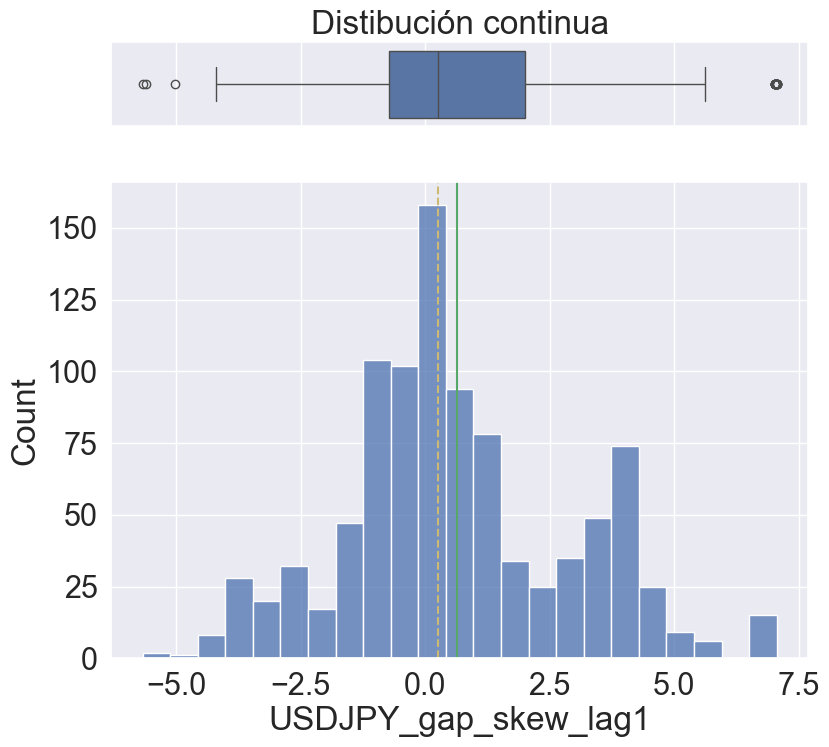

In [31]:
# Visualizar columna
col = 'USDJPY_gap_skew_lag1'
pintar_columna(df_clean[col])

## Correlaciones

In [32]:
# Tabla de Correlaciones general
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
1362,AUDUSD_sma15_pct_diff_sma50_lag1,USDCAD_sma15_pct_diff_sma50_lag1,0.835200
2208,USDCHF_gap_skew_lag1,GBPUSD_gap_skew_lag1,0.809015
959,USDCHF_sma15_pct_diff_sma50_lag1,EURUSD_sma15_pct_diff_sma50_lag1,0.785837
2846,USDCHF_variance_lag1_log,EURUSD_variance_lag1_log,0.750073
527,USDCAD_acceleration_zscore_lag1,USDCAD_return_zscore_lag1,0.748847
915,USDCHF_range10_position_lag1,EURUSD_range10_position_lag1,0.746124
779,USDCHF_acceleration_zscore_lag1,USDCHF_return_zscore_lag1,0.728452
3621,AUDUSD_vol_directional_lag1_log,AUDUSD_range10_position_lag1,0.726999
3172,EURUSD_vol_directional_lag1_log,EURUSD_range10_position_lag1,0.725055
789,USDCHF_ret_diff_zscore_lag1,EURUSD_ret_diff_zscore_lag1,0.723659


In [33]:
# Correlaciones con la variable objetivo continua
simbolo_objetivo = 'EURUSD'
objetivo = f"{simbolo_objetivo}_intra_weekly"

top_correlaciones_objetivo(df=df_clean, target_col=objetivo)

,Variable,Correlación
0,USDCHF_intra_weekly,-0.674738
1,GBPUSD_intra_weekly,0.631383
2,AUDUSD_intra_weekly,0.490374
3,USDJPY_intra_weekly,-0.347526
4,USDCAD_intra_weekly,-0.343139
5,USDCHF_return_zscore_lag1,0.106649
6,USDCHF_acceleration_zscore_lag1,0.088120
7,GBPUSD_variance_lag1_log,0.083288
8,USDCHF_spread_zscore_lag1_yeo,-0.078413
9,USDCAD_variance_lag1_log,0.073313


## Analisis de label categorica

In [34]:
# Filtrar pares restantes
df_filtrado = filtrar_pares_restantes(df_clean,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df_filtrado.index.max()
df_train, df_live = separar_datos_live(df=df_filtrado, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles

objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )


print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker EURUSD ---
   categoria  lim_inferior  lim_superior
0          1     -0.039486     -0.003884
1          2     -0.003884      0.005259
2          3      0.005259      0.045143


In [35]:
df_train[objetivo_cat].value_counts()

EURUSD_intra_weekly_cat
1    321
3    321
2    320
Name: count, dtype: int64



In [36]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]


pintar_violin_plots(
    df=df_train,
    numeric_cols=numeric_cols,
    target_col=target_col
)